# VAD: offline detection and segmentation

English | [简体中文](02_detect_and_segment.zh-CN.ipynb)

## Goal

Use the same implementation as the CLI. The default synthetic CPU tutorial verifies mechanics, not speech quality. Real Silero adapts only its selected decoder; this tutorial's random small feature projection is **not pretrained Silero**.

## Setup

Locally install `.[vad,notebooks,publish]` in a matching kernel. The next cell installs only in Colab. VAD requires no Transformers dependency. Keep private recordings and long-running outputs on persistent storage. No uploads occur in this notebook.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path("/content/advai-notebooks")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}[vad,notebooks,publish]"], check=True)
else:
    ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                if (path / "pyproject.toml").is_file())
print("Repository and VAD environment ready.")

Repository and VAD environment ready.


### Parameters and imports

A fresh output path makes the tutorial safe to rerun. The YAML records the seed, thresholds, sample rate and optimizer.

In [2]:
import json
import uuid
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, Markdown, display
from advai_notebooks.vad.config import load_config
from advai_notebooks.vad.data import load_data, prepare_data
from advai_notebooks.vad.model import VADModel
from advai_notebooks.vad.pipeline import run
from advai_notebooks.vad.publish import publish
from advai_notebooks.vad.visualize import plot_detection
from advai_notebooks.common.runtime import setup

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
cfg = load_config(ROOT / "configs/vad/smoke.yaml", ROOT)
cfg.output_dir = f"outputs/vad/02_detect_and_segment-{uuid.uuid4().hex[:8]}"
print({"backend": cfg.model.id, "sample_rate": cfg.model.sample_rate,
       "seed": cfg.training.seed, "frame_seconds": 0.032})

{'backend': 'tiny', 'sample_rate': 16000, 'seed': 42, 'frame_seconds': 0.032}


## Steps

### 1. Choose an inference export

The default creates a tiny synthetic demonstration export. Set `CHECKPOINT` to your own trusted VAD export to skip training. Real native inference can also initialize `VADModel` directly from the pinned `silero.yaml` model settings; training data is not needed for detection.

In [3]:
CHECKPOINT = None  # Set to a trusted native export for real recordings.
if CHECKPOINT is None:
    report = run(cfg)
    CHECKPOINT = report["export"]
model = VADModel.load(CHECKPOINT, "cpu")
AUDIO_PATH = ROOT / "data/sample/vad/audio/one.wav"
REFERENCE = [{"start": 0.32, "end": 0.8}, {"start": 1.12, "end": 1.6}]
# Change AUDIO_PATH and REFERENCE together; use None if annotations are unavailable.
print({"backend": model.settings.id, "threshold": model.settings.threshold,
       "exit_threshold": model.settings.exit_threshold})

{'backend': 'tiny', 'threshold': 0.4, 'exit_threshold': 0.25}


### 2. Detect and visualize

Probabilities are not transcripts. Hysteresis, short-silence merging, duration filtering and padding all affect boundaries. This plot uses synthetic tones and cannot demonstrate real speech quality.

{'duration_seconds': 2.0, 'speech_segments': [{'start': 0, 'end': 2.0}]}


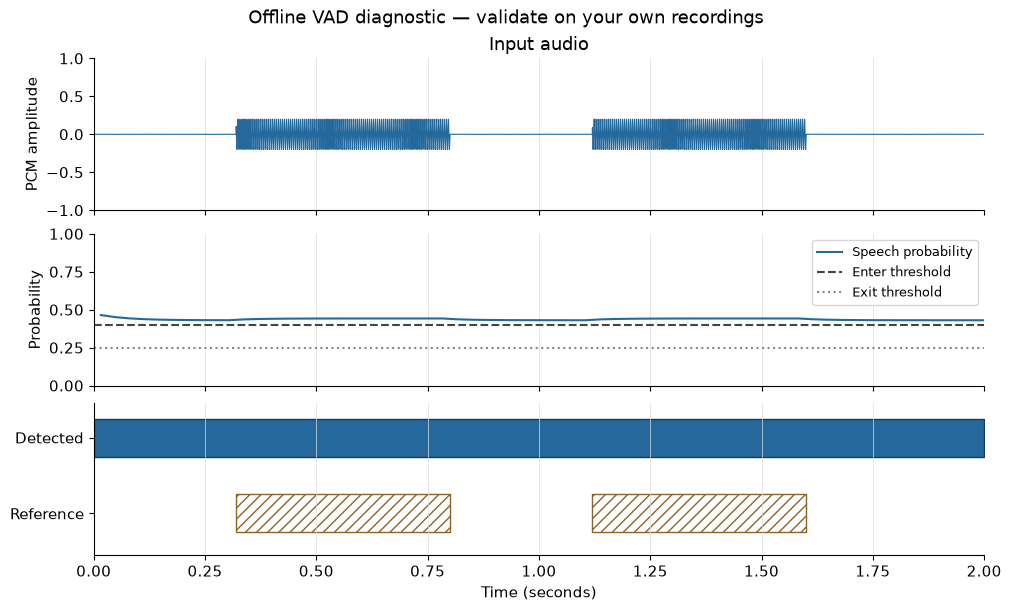

In [4]:
detection = model.detect(AUDIO_PATH)
print({"duration_seconds": detection["duration"],
       "speech_segments": detection["speech_segments"]})
figure = plot_detection(detection, model.settings, REFERENCE)
figure.suptitle("Offline VAD diagnostic — validate on your own recordings")
cfg.path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
figure.savefig(cfg.path(cfg.output_dir) / "timeline.png", dpi=140)
plt.show()

### 3. Write bounded chunks with original offsets

A new destination protects existing audio. This demonstration uses 0.4-second chunks to expose offsets; real Whisper inference can use a limit up to 30 seconds. No speech yields no chunks.

In [5]:
result = model.segment(AUDIO_PATH, cfg.path(cfg.output_dir) / "chunks",
                       max_chunk_duration=0.4)
print({"chunks": len(result["chunks"]), "contains_transcript_labels": False})
for chunk in result["chunks"][:5]:
    print({key: round(chunk[key], 4) for key in ("source_start", "source_end", "duration")})
if result["chunks"]:
    display(Audio(filename=result["chunks"][0]["audio"]))

{'chunks': 5, 'contains_transcript_labels': False}
{'source_start': 0.0, 'source_end': 0.4, 'duration': 0.4}
{'source_start': 0.4, 'source_end': 0.8, 'duration': 0.4}
{'source_start': 0.8, 'source_end': 1.2, 'duration': 0.4}
{'source_start': 1.2, 'source_end': 1.6, 'duration': 0.4}
{'source_start': 1.6, 'source_end': 2.0, 'duration': 0.4}


## Checks

Check source offsets, chunk duration and safe reruns. The chunk manifest contains no transcript. Align labels before using it for supervised STT training.

In [6]:
for chunk in result["chunks"]:
    assert 0 <= chunk["source_start"] < chunk["source_end"] <= result["duration"]
    assert chunk["duration"] <= 0.4 + 1 / model.settings.sample_rate
    assert "text" not in chunk
try:
    model.segment(AUDIO_PATH, cfg.path(cfg.output_dir) / "chunks")
except ValueError as error:
    print("Existing destination correctly refused.")
else:
    raise AssertionError("Existing chunks must never be overwritten")

Existing destination correctly refused.


## Next Steps

Read the [full guide](../../docs/vad.md). For real training, copy `configs/vad/silero.yaml` into ignored `configs/local/`, use consented fully annotated audio and independent recording groups. Do not train the real model on these tones. For STT inference, transcribe chunks and merge using source offsets. For TTS, inspect leading/trailing silence without automatically removing sentence-internal pauses. GPU/Colab fit, real-time performance and target-domain speech quality are not established here.